In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt

In [3]:
import seaborn as sns

In [8]:
df = pd.read_csv("cleaned_data.csv",encoding="latin1")

In [9]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [12]:
print(type(df))
print(df.columns)

<class 'pandas.core.frame.DataFrame'>
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')


In [13]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"] = df["CustomerID"].astype("Int64")
df = df.dropna(subset=["CustomerID"])
df = df[(df["Quantity"] > 0) &(df["UnitPrice"] > 0)]
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [15]:
import pandas as pd
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"] = df["CustomerID"].astype("Int64")
df = df.dropna(subset=["CustomerID"])
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
print("Cleaned rows:", len(df))
print("Unique customers:", df["CustomerID"].nunique())

Cleaned rows: 392692
Unique customers: 4338


In [16]:
import pandas as pd
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"))
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [17]:
rfm["R_Score"] = pd.qcut(rfm["Recency"].rank(method="first"),4,labels=[4, 3, 2, 1])
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"),4,labels=[1, 2, 3, 4])
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"),4,labels=[1, 2, 3, 4])
rfm["RFM_Score"] = (rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str))
rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346,326,1,77183.60,1,1,4,114
12347,2,7,4310.00,4,4,4,444
12348,75,4,1797.24,2,3,4,234
12349,19,1,1757.55,3,1,4,314
12350,310,1,334.40,1,1,2,112


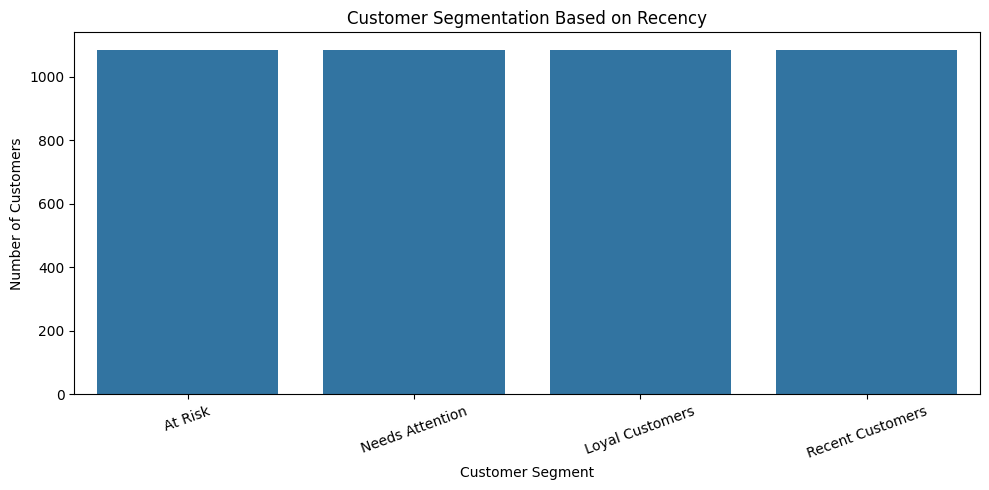

In [18]:
rfm["Segment"] = pd.cut(rfm["R_Score"].astype(int),bins=[0, 1, 2, 3, 4],labels=["At Risk","Needs Attention","Loyal Customers","Recent Customers"])
segment_counts = rfm["Segment"].value_counts().sort_index()
plt.figure(figsize=(10, 5))
sns.barplot(x=segment_counts.index, y=segment_counts.values)
plt.title("Customer Segmentation Based on Recency")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

RFM Analysis – Key Insights

RFM analysis helps identify customer purchasing behaviour using three metrics:

- Recency: How recently a customer made a purchase.
- Frequency: How often a customer purchased.
- Monetary: How much money a customer spent.

Business Impact

- Identify customers who may need special offers to return.
- Recognize frequent customers and encourage repeat purchases.
- Identify high-spending customers for targeted marketing campaigns.
- Help the business improve cus